**Датасет:** https://allisonhorst.github.io/palmerpenguins/

# Лабораторная работа №3. Дополнительное задание
### Глубокая кластеризация (DEC)

### 1) Цель

Освоить пайплайн глубокой кластеризации: архитектура, обучение, подбор гиперпараметров, сравнение с классическими методами и интерпретация групп.

Данные те же, что в основной работе: четыре промера пингвинов. Вид в обучение не входит и нужен только для внешних метрик.

### 2) Загрузка и подготовка

Строк после очистки: 342, пропусков в промерах: 0
Вид
Адели             151
Папуанский        123
Антарктический     68
Асимметрия:
Длина клюва, мм       0.05
Высота клюва, мм     -0.14
Длина плавника, мм    0.35
Масса тела, г         0.47


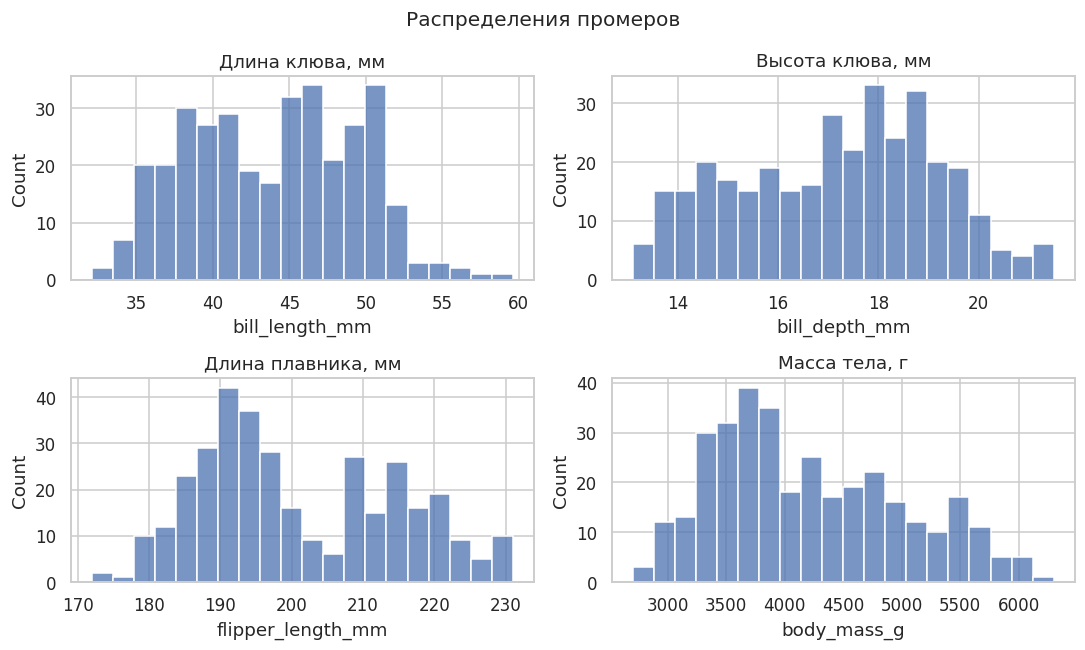

Матрица: (342, 4)


In [1]:
%matplotlib inline
import os
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE
from sklearn.metrics import (
    silhouette_score, calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score, homogeneity_score, completeness_score,
)

tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.autolayout"] = True

SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

RU = {
    "bill_length_mm": "Длина клюва, мм",
    "bill_depth_mm": "Высота клюва, мм",
    "flipper_length_mm": "Длина плавника, мм",
    "body_mass_g": "Масса тела, г",
}
MEASURES = list(RU)
SPECIES = {"Adelie": "Адели", "Chinstrap": "Антарктический", "Gentoo": "Папуанский"}

raw = pd.read_csv("data/penguins.csv")
df = raw.dropna(subset=MEASURES).reset_index(drop=True)
df["Вид"] = df["species"].map(SPECIES)
print(f"Строк после очистки: {len(df)}, пропусков в промерах: {int(df[MEASURES].isna().sum().sum())}")
print(df["Вид"].value_counts().to_string())
print("Асимметрия:")
print(df[MEASURES].skew().rename(RU).round(2).to_string())

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.ravel(), MEASURES):
    sns.histplot(df[col], bins=20, ax=ax, color="#4C72B0")
    ax.set_title(RU[col])
fig.suptitle("Распределения промеров")
plt.show()

X = StandardScaler().fit_transform(df[MEASURES].to_numpy(dtype=np.float32)).astype(np.float32)
y_species = df["Вид"].to_numpy()
print("Матрица:", X.shape)

### Вывод о пригодности

342 птицы и 4 числовых промера. Пропуски в промерах удалены. Распределения без тяжёлых денежных хвостов, стандартизация выравнивает граммы и миллиметры. В основной работе на этих данных уже видны два плотных сгущения. Размерность низкая, поэтому глубокая модель обязана доказать, что сжатие отделяет группы лучше K-средних в исходном пространстве.

### 3) Архитектура DEC

Выбран Deep Embedded Clustering.

- Энкодер: слой на 16 нейронов ReLU и линейный латентный слой. Вход из 4 промеров, скрытый слой даёт нелинейную комбинацию, латентность меньше входа.
- Декодер симметричен, выход линейный: восстановление идёт в стандартизированной шкале.
- Предобучение минимизирует MSE.
- Центры задаёт K-средних в коде, `n_init=10`.
- Дообучение минимизирует KL между целевым распределением \(p_{ij} \propto q_{ij}^2 / f_j\) и мягкими назначениями Стьюдента. Декодер на этом шаге заморожен. Регуляризация — L2, она входит в сетку.

In [2]:
def build_models(n_features, latent, l2, lr):
    regularizer = tf.keras.regularizers.l2(l2) if l2 else None
    inputs = tf.keras.Input(shape=(n_features,))
    hidden = tf.keras.layers.Dense(16, activation="relu", kernel_regularizer=regularizer)(inputs)
    latent_layer = tf.keras.layers.Dense(latent, name="latent", kernel_regularizer=regularizer)(hidden)
    decoded = tf.keras.layers.Dense(16, activation="relu", kernel_regularizer=regularizer)(latent_layer)
    outputs = tf.keras.layers.Dense(n_features)(decoded)
    autoencoder = tf.keras.Model(inputs, outputs)
    encoder = tf.keras.Model(inputs, latent_layer)
    autoencoder.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="mse")
    return autoencoder, encoder


def soft_assign(codes, centers, alpha=1.0):
    distance = tf.reduce_sum(tf.square(codes[:, None, :] - centers[None, :, :]), axis=2)
    weights = tf.pow(1.0 + distance / alpha, -(alpha + 1.0) / 2.0)
    return weights / tf.reduce_sum(weights, axis=1, keepdims=True)


def target_distribution(q_values):
    frequency = tf.reduce_sum(q_values, axis=0, keepdims=True)
    sharpened = tf.square(q_values) / tf.maximum(frequency, 1e-8)
    return sharpened / tf.reduce_sum(sharpened, axis=1, keepdims=True)


def safe_silhouette(features, labels):
    if len(np.unique(labels)) < 2 or len(np.unique(labels)) >= len(labels):
        return np.nan
    return float(silhouette_score(features, labels))


def run_dec(features, latent, n_clusters, lr, l2, pre_epochs, ft_epochs, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    autoencoder, encoder = build_models(features.shape[1], latent, l2, lr)
    history = autoencoder.fit(features, features, epochs=pre_epochs, batch_size=32, verbose=0)
    codes = encoder(features, training=False).numpy()
    initial = KMeans(n_clusters=n_clusters, n_init=10, random_state=seed).fit(codes)
    labels_before = initial.labels_.copy()
    centers = tf.Variable(initial.cluster_centers_.astype(np.float32))
    optimizer = tf.keras.optimizers.Adam(lr)
    index = np.arange(len(features))
    rng = np.random.default_rng(seed)
    kl_trace = []
    for _ in range(ft_epochs):
        q_full = soft_assign(encoder(features, training=False), centers)
        target = tf.stop_gradient(target_distribution(q_full)).numpy()
        rng.shuffle(index)
        batch_losses = []
        for start in range(0, len(features), 64):
            batch = index[start:start + 64]
            x_batch = tf.constant(features[batch])
            p_batch = tf.constant(target[batch])
            with tf.GradientTape() as tape:
                q_batch = tf.clip_by_value(soft_assign(encoder(x_batch, training=True), centers), 1e-8, 1.0)
                p_clip = tf.clip_by_value(p_batch, 1e-8, 1.0)
                loss = tf.reduce_mean(tf.reduce_sum(p_clip * tf.math.log(p_clip / q_batch), axis=1))
            variables = encoder.trainable_variables + [centers]
            optimizer.apply_gradients(zip(tape.gradient(loss, variables), variables))
            batch_losses.append(float(loss))
        kl_trace.append(float(np.mean(batch_losses)))
    codes_final = encoder(features, training=False).numpy()
    labels = soft_assign(tf.constant(codes_final), centers).numpy().argmax(axis=1)
    return {
        "labels_before": labels_before,
        "labels": labels,
        "codes": codes_final,
        "recon": float(history.history["loss"][-1]),
        "kl_trace": kl_trace,
        "pre_loss": history.history["loss"],
        "silhouette_before": safe_silhouette(features, labels_before),
        "silhouette": safe_silhouette(features, labels),
    }

### 4) Подбор гиперпараметров

Сетка: латентность 2 и 3, число кластеров 2, 3 и 4, скорость 0,001 и 0,0001, L2 0 и 0,0001. Критерий — силуэт в исходном пространстве промеров. Вид в выбор лучшей строки не входит.

z=2, k=2, lr=1e-03, l2=0e+00: sil 0.532


z=2, k=2, lr=1e-03, l2=1e-04: sil 0.532


z=2, k=2, lr=1e-04, l2=0e+00: sil 0.410


z=2, k=2, lr=1e-04, l2=1e-04: sil 0.410


z=2, k=3, lr=1e-03, l2=0e+00: sil 0.453


...

z=3, k=3, lr=1e-04, l2=1e-04: sil 0.270


z=3, k=4, lr=1e-03, l2=0e+00: sil 0.391


z=3, k=4, lr=1e-03, l2=1e-04: sil 0.391


z=3, k=4, lr=1e-04, l2=0e+00: sil 0.227


z=3, k=4, lr=1e-04, l2=1e-04: sil 0.227
 Латентность  k  Скорость     L2    MSE  Силуэт до KL  Силуэт DEC  ARI DEC
           3  2     0.001 0.0000 0.1094        0.5222      0.5315   0.6551
           3  2     0.001 0.0001 0.1113        0.5222      0.5315   0.6551
           2  2     0.001 0.0000 0.1157        0.5315      0.5315   0.6551
           2  2     0.001 0.0001 0.1174        0.5315      0.5315   0.6551
           2  3     0.001 0.0000 0.1157        0.4566      0.4528   0.7740
           2  3     0.001 0.0001 0.1174        0.4566      0.4528   0.7740
           3  3     0.001 0.0000 0.1094        0.4401      0.4416   0.7462
           3  3     0.001 0.0001 0.1113        0.4401      0.4416   0.7462
Выбрано:
Латентность     3.000000
k               2.000000
Скорость        0.001000
L2              0.000000
MSE             0.109419
Силуэт до KL    0.522185
Силуэт DEC      0.531540
ARI DEC         0.655066
Разброс Латентность: 0.0118
Разброс k: 0.1595
Разброс Скорость: 0.1387
Разбр

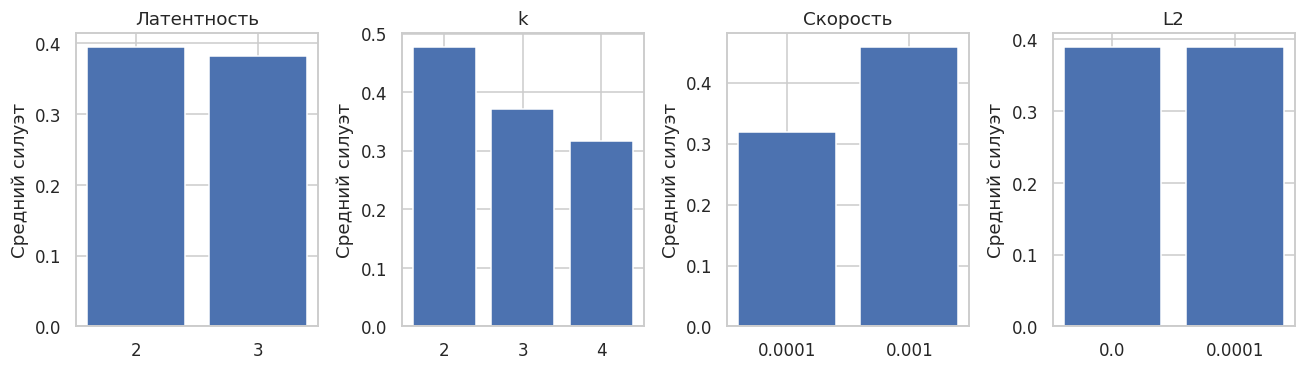

In [3]:
grid_rows = []
for latent in (2, 3):
    for n_clusters in (2, 3, 4):
        for lr in (1e-3, 1e-4):
            for l2 in (0.0, 1e-4):
                trial = run_dec(X, latent, n_clusters, lr, l2, 40, 15, SEED)
                grid_rows.append({
                    "Латентность": latent, "k": n_clusters, "Скорость": lr, "L2": l2,
                    "MSE": trial["recon"],
                    "Силуэт до KL": trial["silhouette_before"],
                    "Силуэт DEC": trial["silhouette"],
                    "ARI DEC": adjusted_rand_score(y_species, trial["labels"]),
                })
                print(f"z={latent}, k={n_clusters}, lr={lr:.0e}, l2={l2:.0e}: sil {trial['silhouette']:.3f}")

grid = pd.DataFrame(grid_rows)
ranked = grid.sort_values(["Силуэт DEC", "MSE"], ascending=[False, True]).reset_index(drop=True)
print(ranked.head(8).round(4).to_string(index=False))
best_row = ranked.iloc[0]
print("Выбрано:")
print(best_row.to_string())
for column in ("Латентность", "k", "Скорость", "L2"):
    means = grid.groupby(column)["Силуэт DEC"].mean()
    print(f"Разброс {column}: {means.max() - means.min():.4f}")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, column in zip(axes, ("Латентность", "k", "Скорость", "L2")):
    means = grid.groupby(column)["Силуэт DEC"].mean()
    ax.bar([str(v) for v in means.index], means.values, color="#4C72B0")
    ax.set_title(column)
    ax.set_ylabel("Средний силуэт")
plt.show()

### 5) Сравнение с классическими методами

Рядом считаются K-средних и Уорд при k = 2, смесь нормальных с выбором k по BIC и DBSCAN по сетке eps и min_samples. Внутренние метрики всех методов, включая DEC, считаются в одном пространстве промеров.

GMM k=2: BIC=2586.8
GMM k=3: BIC=2553.6
GMM k=4: BIC=2613.8
GMM k=5: BIC=2660.8
Выбранное k смеси: 3
DBSCAN eps=0.6, min_samples=4, шум=0.076, силуэт без шума=0.555
              Силуэт  Калински–Харабас  Дэвис–Боулдин    ARI    NMI  Однородность  Полнота
Метод                                                                                     
DEC            0.532           482.191          0.714  0.655  0.767         0.622    1.000
AE + K-means   0.522           471.724          0.741  0.646  0.705         0.575    0.910
K-means        0.532           482.191          0.714  0.655  0.767         0.622    1.000
Уорд           0.532           482.191          0.714  0.655  0.767         0.622    1.000
EM (GMM)       0.455           425.955          0.896  0.960  0.935         0.934    0.936
DBSCAN         0.555           215.354          1.936  0.610  0.639         0.586    0.702


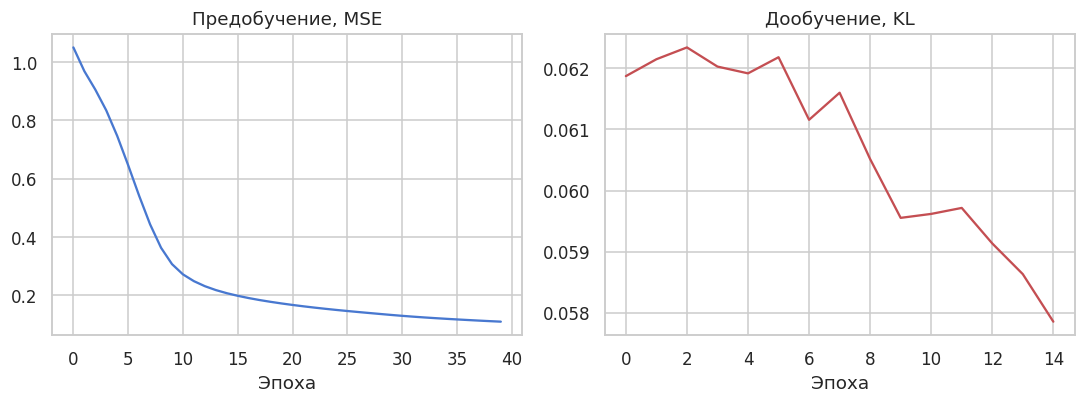

In [4]:
final = run_dec(
    X, int(best_row["Латентность"]), int(best_row["k"]),
    float(best_row["Скорость"]), float(best_row["L2"]), 40, 15, SEED,
)
dec_labels = final["labels"]
km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X)
ag = AgglomerativeClustering(n_clusters=2, linkage="ward").fit(X)

bic_rows = []
for n_components in range(2, 6):
    mixture = GaussianMixture(n_components=n_components, covariance_type="full", n_init=5, random_state=SEED)
    mixture.fit(X)
    bic_rows.append((n_components, float(mixture.bic(X)), mixture.predict(X)))
bic_rows.sort(key=lambda item: item[1])
gmm_k, _, gmm_labels = bic_rows[0]
for n_components, bic, _ in sorted(bic_rows, key=lambda item: item[0]):
    print(f"GMM k={n_components}: BIC={bic:.1f}")
print("Выбранное k смеси:", gmm_k)

db_candidates = []
for eps in np.round(np.linspace(0.3, 1.6, 14), 3):
    for min_samples in (4, 8, 12):
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        n_found = len(set(labels) - {-1})
        noise = float(np.mean(labels == -1))
        if n_found < 2 or noise > 0.30:
            continue
        kept = labels != -1
        db_candidates.append((safe_silhouette(X[kept], labels[kept]), noise, eps, min_samples, labels))
db_candidates = [item for item in db_candidates if np.isfinite(item[0])]
db_candidates.sort(key=lambda item: item[0], reverse=True)
db_sil, db_noise, db_eps, db_min, db_labels = db_candidates[0]
print(f"DBSCAN eps={db_eps}, min_samples={db_min}, шум={db_noise:.3f}, силуэт без шума={db_sil:.3f}")


def pack(name, labels, silhouette_value=None):
    if silhouette_value is None:
        silhouette_value = safe_silhouette(X, labels)
    try:
        calinski = calinski_harabasz_score(X, labels)
        davies = davies_bouldin_score(X, labels)
    except ValueError:
        calinski, davies = np.nan, np.nan
    return {
        "Метод": name,
        "Силуэт": silhouette_value,
        "Калински–Харабас": calinski,
        "Дэвис–Боулдин": davies,
        "ARI": adjusted_rand_score(y_species, labels),
        "NMI": normalized_mutual_info_score(y_species, labels),
        "Однородность": homogeneity_score(y_species, labels),
        "Полнота": completeness_score(y_species, labels),
    }


comparison = pd.DataFrame([
    pack("DEC", dec_labels),
    pack("AE + K-means", final["labels_before"]),
    pack("K-means", km.labels_),
    pack("Уорд", ag.labels_),
    pack("EM (GMM)", gmm_labels),
    pack("DBSCAN", db_labels, silhouette_value=db_sil),
]).set_index("Метод")
print(comparison.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(final["pre_loss"])
axes[0].set_title("Предобучение, MSE")
axes[1].plot(final["kl_trace"], color="#C44E52")
axes[1].set_title("Дообучение, KL")
for ax in axes:
    ax.set_xlabel("Эпоха")
plt.show()

### 6) Визуализация

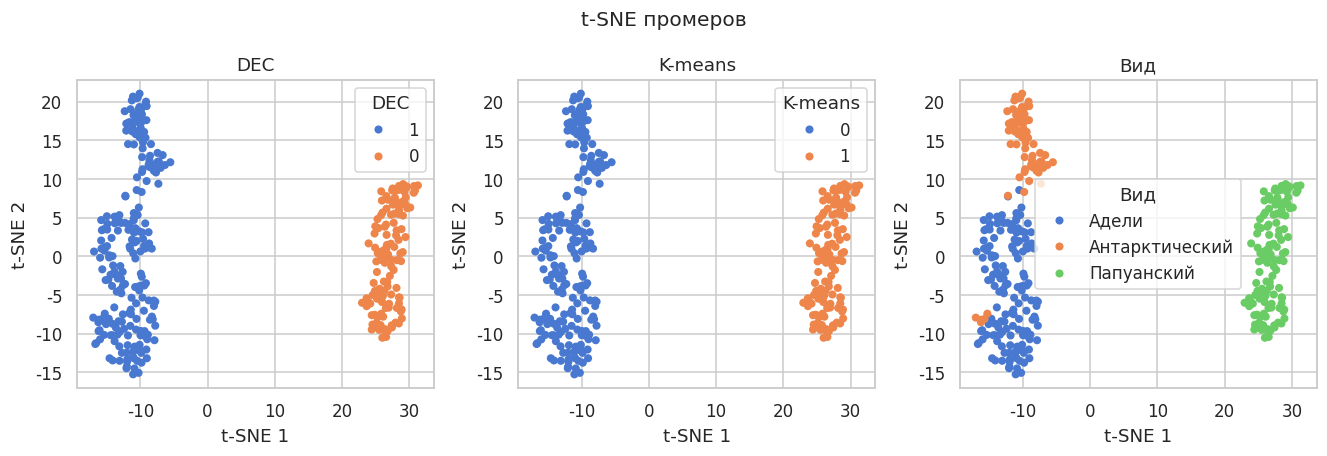

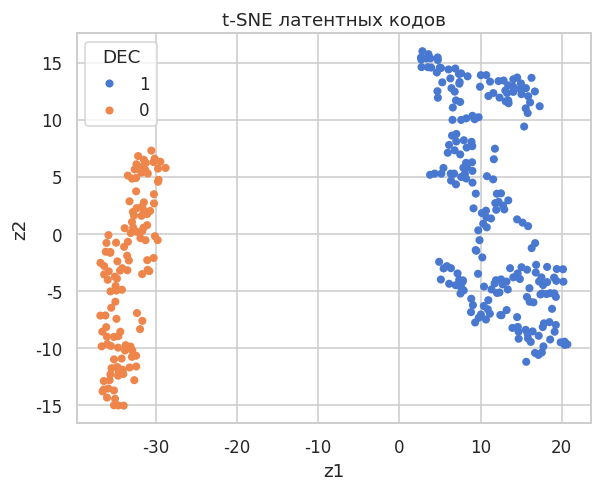

In [5]:
plane = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X)
view = pd.DataFrame({
    "t-SNE 1": plane[:, 0], "t-SNE 2": plane[:, 1],
    "DEC": dec_labels.astype(str),
    "K-means": km.labels_.astype(str),
    "Вид": y_species,
})
fig, axes = plt.subplots(1, 3, figsize=(12.2, 4.2))
for ax, hue in zip(axes, ("DEC", "K-means", "Вид")):
    sns.scatterplot(data=view, x="t-SNE 1", y="t-SNE 2", hue=hue, s=28, ax=ax, linewidth=0)
    ax.set_title(hue)
fig.suptitle("t-SNE промеров")
plt.show()

if final["codes"].shape[1] == 2:
    latent_view = pd.DataFrame({"z1": final["codes"][:, 0], "z2": final["codes"][:, 1], "DEC": dec_labels.astype(str)})
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    sns.scatterplot(data=latent_view, x="z1", y="z2", hue="DEC", s=28, ax=ax, linewidth=0)
    ax.set_title("Латентное пространство DEC")
    plt.show()
else:
    latent_plane = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(final["codes"])
    latent_view = pd.DataFrame({"z1": latent_plane[:, 0], "z2": latent_plane[:, 1], "DEC": dec_labels.astype(str)})
    fig, ax = plt.subplots(figsize=(5.6, 4.6))
    sns.scatterplot(data=latent_view, x="z1", y="z2", hue="DEC", s=28, ax=ax, linewidth=0)
    ax.set_title("t-SNE латентных кодов")
    plt.show()

### 7) Интерпретация и устойчивость

In [6]:
work = df[MEASURES].copy()
work["DEC"] = dec_labels
work["Вид"] = y_species
print("Медианы, DEC")
print(work.groupby("DEC")[MEASURES].median().rename(columns=RU).round(1).to_string())
print(pd.crosstab(work["DEC"], work["Вид"]).to_string())
mass = work.groupby("DEC")["body_mass_g"].median()
print(f"Более тяжёлый кластер: {int(mass.idxmax())}, более лёгкий: {int(mass.idxmin())}")

repeat = run_dec(
    X, int(best_row["Латентность"]), int(best_row["k"]),
    float(best_row["Скорость"]), float(best_row["L2"]), 40, 15, seed=7,
)
km_other = KMeans(n_clusters=2, n_init=10, random_state=7).fit_predict(X)
print(f"ARI двух запусков DEC: {adjusted_rand_score(dec_labels, repeat['labels']):.3f}")
print(f"ARI двух запусков K-means: {adjusted_rand_score(km.labels_, km_other):.3f}")
print(f"Силуэт DEC {comparison.loc['DEC', 'Силуэт']:.3f}, K-means {comparison.loc['K-means', 'Силуэт']:.3f}")
print(f"ARI DEC {comparison.loc['DEC', 'ARI']:.3f}, K-means {comparison.loc['K-means', 'ARI']:.3f}")

Медианы, DEC
     Длина клюва, мм  Высота клюва, мм  Длина плавника, мм  Масса тела, г
DEC                                                                      
0               47.3              15.0               216.0         5000.0
1               40.6              18.4               191.0         3700.0
Вид  Адели  Антарктический  Папуанский
DEC                                   
0        0               0         123
1      151              68           0
Более тяжёлый кластер: 0, более лёгкий: 1


ARI двух запусков DEC: 0.908
ARI двух запусков K-means: 1.000
Силуэт DEC 0.532, K-means 0.532
ARI DEC 0.655, K-means 0.655


### 8) Заключение

По силуэту в пространстве промеров выбраны латентность **3**, **k = 2**, скорость **0,001** и L2 **0**. MSE предобучения — **0,109**. Силуэт до шага KL равен **0,522**, после DEC — **0,532**, ARI с видом — **0,655**.

Те же числа у K-средних и Уорда: силуэт **0,532**, Калински–Харабас **482**, Дэвис–Боулдин **0,714**, ARI **0,655**, полнота **1,000**. DEC повторяет их границу. Кластер 0 — 123 папуанских пингвина, медиана массы **5000** г. Кластер 1 — 151 Адели и 68 антарктических, медиана массы **3700** г. Два запуска DEC согласованы с ARI **0,908**, два запуска K-средних — с ARI **1,000**.

По среднему силуэту сильнее всего влияют k (разброс **0,160**) и скорость (**0,139**). Латентность сдвигает силуэт на **0,012**, L2 — на **0**. Скорость 0,0001 недообучает автоэнкодер.

Смесь нормальных по BIC берёт k = 3 (BIC **2554** против **2587** при k = 2). Её ARI с видом **0,960**, но силуэт падает до **0,455**. DBSCAN при eps = 0,6 и min_samples = 4 помечает шумом **7,6%** птиц. Силуэт **0,555** посчитан только по оставшимся точкам, индекс Калински–Харабаса падает до **215**, Дэвис–Боулдин растёт до **1,936**, ARI равен **0,610**.

На четырёх промерах DEC не обгоняет K-средних. Группы выпуклые, и классический метод устойчивее. Смесь с тремя компонентами ближе к трём видам, если критерием считать внешнюю метку, а не силуэт.

### Источники

1. Xie J., Girshick R., Farhadi A. Unsupervised Deep Embedding for Clustering Analysis. ICML, 2016.
2. Horst A. M., Hill A. P., Gorman K. B. palmerpenguins. 2020. https://allisonhorst.github.io/palmerpenguins/
3. Pedregosa F. et al. Scikit-learn. JMLR, 12, 2011.